In [1]:
%load_ext autoreload
%autoreload 2

subject (1, 1) uint8
exercise (1, 1) uint8
emg (2292526, 16) float32
acc (2292526, 48) float32
gyro (2292526, 48) float32
mag (2292526, 48) float32
glove (2292526, 18) float32
stimulus (2292526, 1) int8
repetition (2292526, 1) int8
restimulus (2292526, 1) int8
rerepetition (2292526, 1) int8
duration (s): 1146.263
movements: [0 1 2 3 4 5 6 7 8 9]
repetitions: [ 0  1  2  3  4  5  6  7  8  9 10]


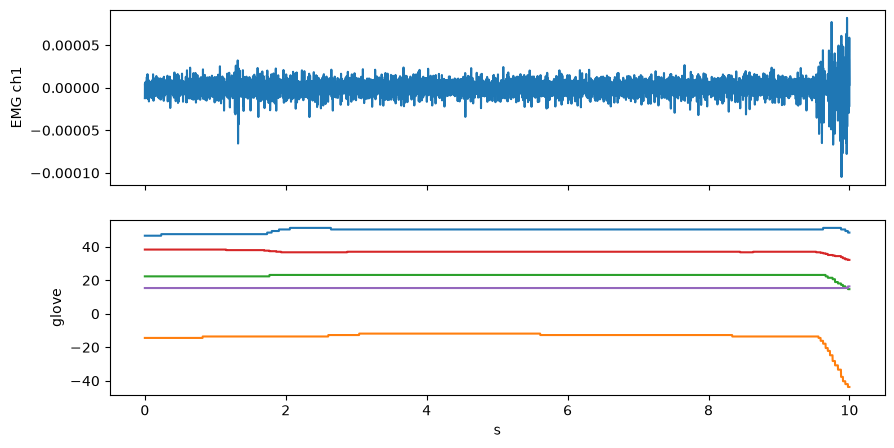

In [1]:
import numpy as np, scipy.io as sio, matplotlib.pyplot as plt
path = r"D:\emg-project\data\raw\DB8\S1_E1_A1.mat"   # adjust the name
try:
    d = sio.loadmat(path); keys = [k for k in d if not k.startswith("__")]
    get = lambda k: d[k]
except NotImplementedError:          # newer MATLAB v7.3 format
    import h5py; f = h5py.File(path, "r"); keys = list(f.keys())
    get = lambda k: np.array(f[k]).T
for k in keys:
    try: a = get(k); print(k, a.shape, a.dtype)
    except Exception as e: print(k, "could not read:", e)
emg, glove = get("emg"), get("glove")
print("duration (s):", emg.shape[0] / 2000)
print("movements:", np.unique(get("restimulus")))
print("repetitions:", np.unique(get("rerepetition")))
t = np.arange(20000) / 2000
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 5))
ax[0].plot(t, emg[:20000, 0]); ax[0].set_ylabel("EMG ch1")
ax[1].plot(t, glove[:20000, :5]); ax[1].set_ylabel("glove"); ax[1].set_xlabel("s")
plt.show()